In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [4]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int        
    return hist, errs, bins

In [5]:
observables = ['evid','xsec','pt','eta']

In [10]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_20pthat25_eta.txt']

In [12]:
df = pd.read_csv(files[0], names=observables, low_memory=False)

In [30]:
plt.rcParams['font.size'] = '12'

number of jets in eta of [-1.6,1.6]: 300798
number of jets in eta of [-1.0,1.0]: 246661
number of jets in eta of [-0.6,0.6]: 164507


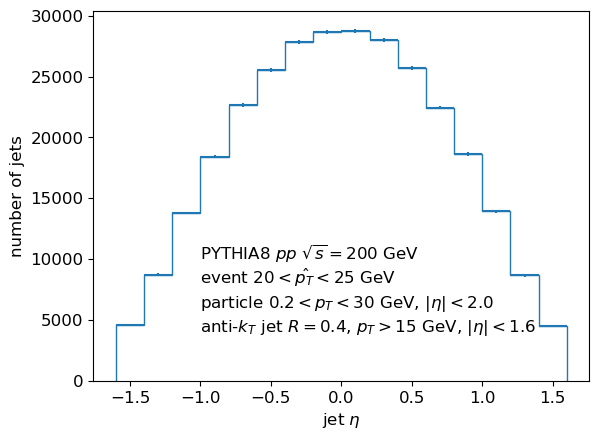

In [39]:
plt.hist(df['eta'], bins=np.arange(-1.6,1.8,0.2), histtype='step')
plt.errorbar(np.arange(-1.5,1.7,0.2), y, xerr=0.1, yerr=yerr, ls='none', color='tab:blue')
plt.xlabel('jet $\eta$')
plt.ylabel('number of jets')
plt.text(-1.0, 10000, 'PYTHIA8 $pp$ $\sqrt{s}=200$ GeV')
plt.text(-1.0, 8000, 'event $20<\hat{p_T}<25$ GeV')
plt.text(-1.0, 6000, 'particle $0.2<p_T<30$ GeV, $|\eta|<2.0$')
plt.text(-1.0, 4000, 'anti-$k_T$ jet $R=0.4$, $p_T>15$ GeV, $|\eta|<1.6$')
print('number of jets in eta of [-1.6,1.6]:', df.shape[0])
print('number of jets in eta of [-1.0,1.0]:', df[(df.eta<1.0) & (df.eta>-1.0)].shape[0])
print('number of jets in eta of [-0.6,0.6]:', df[(df.eta<0.6) & (df.eta>-0.6)].shape[0])